# Example training and evaluation of LightGBM model

In [ ]:
import lightgbm, sklearn, matplotlib, seaborn

print("lightgbm:     ", lightgbm.__version__)
print("scikit-learn: ", sklearn.__version__)
print("matplotlib:   ", matplotlib.__version__)
print("seaborn:      ", seaborn.__version__)

lightgbm:      4.6.0
scikit-learn:  1.6.1
matplotlib:    3.10.0
seaborn:       0.13.2


In [ ]:
# import sys
# !{sys.executable} -m pip install cesnet-datazoo lightgbm scikit-learn matplotlib seaborn

!pip install cesnet-datazoo -q #  lightgbm scikit-learn matplotlib seaborn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.6/68.6 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 444.8/444.8 kB 12.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 51.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-genai 2.12.1 requires pydantic<3.0.0,>=2.12.5, but you have pydantic 2.11.10 which is incompatible.
google-adk 2.7.1 requires pydantic<3,>=2.12, but you have pydantic 2.11.10 which is incompatible.


Download the CESNET-QUIC22 dataset if it is not already downloaded, enable logging, and set configuration.

In [ ]:
!pip install zenodo-get -q
!zenodo_get 10728760

INFO: Output directory: /content
INFO: Title: CESNET-QUIC22: A large one-month QUIC network traffic dataset from backbone lines
INFO: Total size: 21.0 GB
INFO: Number of files: 2
Files:   0% 0/2 [00:00<?, ?file/s]^C


In [ ]:
# под винду
# curl.exe -L -C - -o cesnet-quic22.zip "https://zenodo.org/records/10728760/files/cesnet-quic22.zip?download=1"

In [ ]:
# !wget https://liberouter.org/datazoo/download?bucket=cesnet-quic22&file=CESNET-QUIC22-XS.h5
# !wget -O cesnet-quic22.zip "https://zenodo.org/records/10728760/files/cesnet-quic22.zip?download=1"

!wget -O cesnet-tls22.zip "https://zenodo.org/records/10610895/files/cesnet-tls22.zip?download=1"

--2026-10-16 19:55:32--  https://zenodo.org/records/10610895/files/cesnet-tls22.zip?download=1
Resolving zenodo.org (zenodo.org)... 188.185.40.132, 188.185.51.60, 188.185.45.63, ...
Connecting to zenodo.org (zenodo.org)|188.185.40.132|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 9482192513 (8.8G) [application/octet-stream]
Saving to: ‘cesnet-tls22.zip’

cesnet-tls22.zip    100%[===================>]   8.83G  5.34MB/s    in 44m 22s 

2026-10-16 20:39:55 (3.40 MB/s) - ‘cesnet-tls22.zip’ saved [9482192513/9482192513]



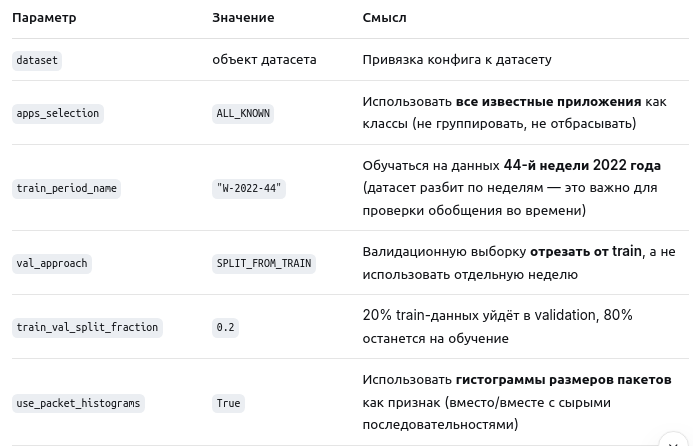

In [ ]:
import logging
from cesnet_datazoo.datasets import CESNET_QUIC22
# from cesnet_datazoo.datasets import CESNET_TLS22
from cesnet_datazoo.config import DatasetConfig, ValidationApproach, AppSelection

# Просто красиво форматирует сообщения в консоли: [время][модуль][уровень] - текст.
logging.basicConfig(
    level=logging.INFO,
    format="[%(asctime)s][%(name)s][%(levelname)s] - %(message)s")

dataset = CESNET_QUIC22(data_root="data/CESNET-QUIC22/", size="S") # XS, S, M, L
# dataset = CESNET_TLS22(data_root="data/CESNET-TLS22/", size="XS") # XS, S, M, L
common_params = {
    "dataset": dataset,
    "apps_selection": AppSelection.ALL_KNOWN,
    "train_period_name": "W-2022-44",
    "val_approach": ValidationApproach.SPLIT_FROM_TRAIN,
    "train_val_split_fraction": 0.2,
    "use_packet_histograms": True,
}
dataset_config = DatasetConfig(**common_params)
dataset.set_dataset_config_and_initialize(dataset_config)

The dataset hosting server is unreachable. Please contact us at https://github.com/CESNET/cesnet-datazoo/issues.


HTTPError: 503 Server Error: Service Unavailable for url: https://liberouter.org/datazoo/download?bucket=cesnet-quic22&file=CESNET-QUIC22-S.h5

Load training and validation dataframes and create LightGBM datasets.

In [ ]:
import lightgbm as lgb
from cesnet_datazoo.constants import APP_COLUMN

# возвращает список имён колонок-признаков, которые будут подаваться в модель.
# flatten_ppi=True — «flatten Packet Packet Interval / packet size histograms»: гистограммы размеров пакетов
# разворачиваются в плоский вектор (каждый бин становится отдельной колонкой).
# Без этого была бы вложенная структура, непригодная для LightGBM.
# Пример: ["PPI_0", "PPI_1", ..., "PPI_255"] — по одному значению на каждый размер пакета.
feature_names = dataset_config.get_feature_names(flatten_ppi=True)

# возвращает pandas.DataFrame с обучающими данными: строки = сессии/потоки трафика, колонки = признаки + метка APP_COLUMN.
train_df      = dataset.get_train_df(flatten_ppi=True)
val_df        = dataset.get_val_df(flatten_ppi=True)

# удаляет колонку APP из датафрейма, возвращает её как pandas.Series.
train_labels  = train_df.pop(APP_COLUMN)
val_labels    = val_df.pop(APP_COLUMN)

# lgb.Dataset — внутренний формат LightGBM, оптимизированный для обучения:
#     data — матрица признаков,
#     label — целевая переменная,
# feature_name — имена колонок (для важности признаков и читаемых логов).
# Сами данные пока не материализуются — LightGBM лениво построит бины при первом использовании в lgb.train(...).
lgb_train_dataset = lgb.Dataset(data=train_df, label=train_labels, feature_name=feature_names)
lgb_val_dataset   = lgb.Dataset(data=val_df,   label=val_labels, feature_name=feature_names)

print(f"Loaded {len(train_df)} train samples")
print(f"Loaded {len(val_df)} validation samples")

Loading data from dataloader


100%|██████████| 8162/8162 [00:04<00:00, 1948.02it/s]


Loading data from dataloader


100%|██████████| 192/192 [00:00<00:00, 237.50it/s]


Loaded 1566944 train samples
Loaded 391736 validation samples


Train the LightGBM model for 20 iterations.

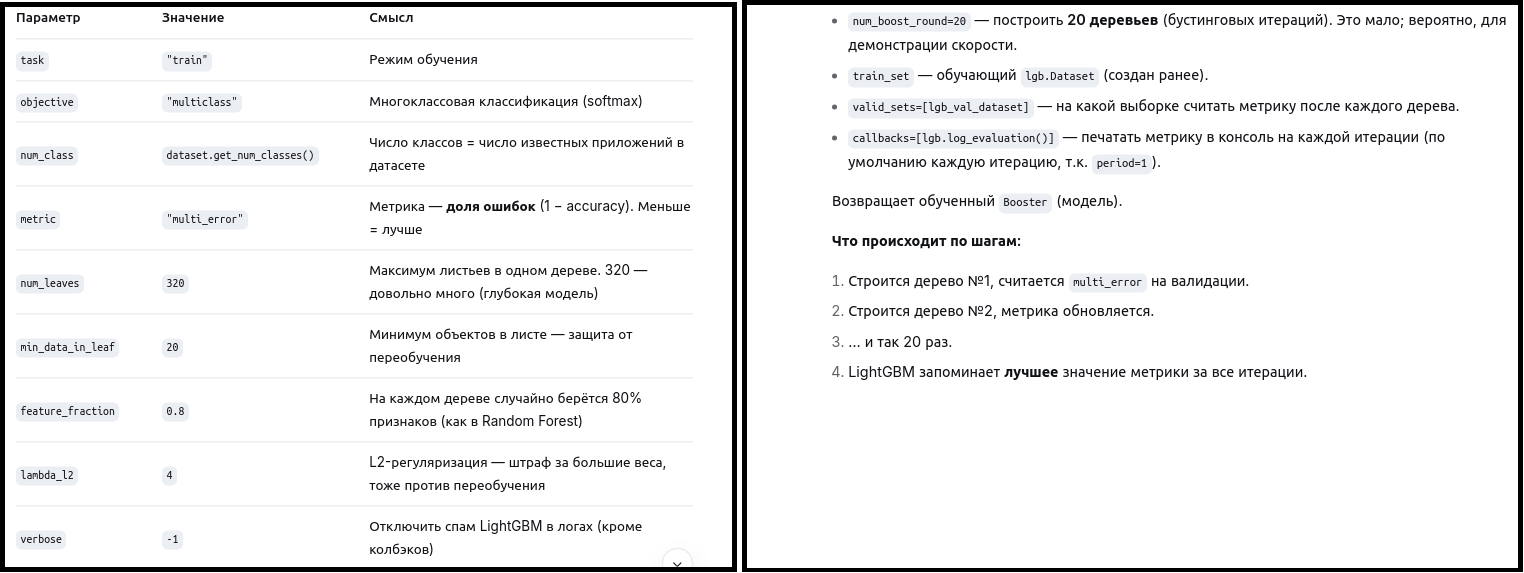

In [ ]:
lgb_params = {
    "task"            : "train",
    "objective"       : "multiclass",
    "num_class"       : dataset.get_num_classes(),
    "metric"          : "multi_error",
    "num_leaves"      : 320,
    "min_data_in_leaf": 20,
    "feature_fraction": 0.8,
    "lambda_l2"       : 4,
    "verbose"         : -1,
}

validation_metrics = {}
lgb_model = lgb.train(
    params          = lgb_params,
    num_boost_round = 20,
    train_set       = lgb_train_dataset,
    valid_sets      = [lgb_val_dataset],
    callbacks       = [lgb.log_evaluation()]
)
best_score = lgb_model.best_score["valid_0"]["multi_error"]
print(f"The best validation score is {best_score:.3f}")

[1]	valid_0's multi_error: 0.2201
[2]	valid_0's multi_error: 0.18671
[3]	valid_0's multi_error: 0.169668
[4]	valid_0's multi_error: 0.156833
[5]	valid_0's multi_error: 0.148156
[6]	valid_0's multi_error: 0.141858
[7]	valid_0's multi_error: 0.13591
[8]	valid_0's multi_error: 0.131326
[9]	valid_0's multi_error: 0.127297
[10]	valid_0's multi_error: 0.12366
[11]	valid_0's multi_error: 0.119966
[12]	valid_0's multi_error: 0.117048
[13]	valid_0's multi_error: 0.114202
[14]	valid_0's multi_error: 0.111922
[15]	valid_0's multi_error: 0.109793
[16]	valid_0's multi_error: 0.107687
[17]	valid_0's multi_error: 0.10574
[18]	valid_0's multi_error: 0.10394
[19]	valid_0's multi_error: 0.10223
[20]	valid_0's multi_error: 0.100693
The best validation score is 0.101


## Per-week evaluation

Training of the model was done on samples of the first (44th week of 2022) week of CESNET-QUIC22. Now, let's evaluate the model on the following three weeks (45th, 46th, and 47th).

For each week:

1. Create ``DatasetConfig`` and set the week as ``test_period_name``.
2. Load test dataframe.
3. Predict applications with the trained LightGBM model.
4. Compute classification accuracy.


Testing on period W-2022-45
Loading data from dataloader


100%|██████████| 1247/1247 [00:14<00:00, 85.99it/s] 


Loaded 2551901 test samples
Classification accuracy for W-2022-45 is 0.816

Testing on period W-2022-46
Loading data from dataloader


100%|██████████| 985/985 [00:13<00:00, 70.74it/s] 


Loaded 2016733 test samples
Classification accuracy for W-2022-46 is 0.722

Testing on period W-2022-47
Loading data from dataloader


100%|██████████| 1289/1289 [00:15<00:00, 84.98it/s] 


Loaded 2639441 test samples
Classification accuracy for W-2022-47 is 0.714


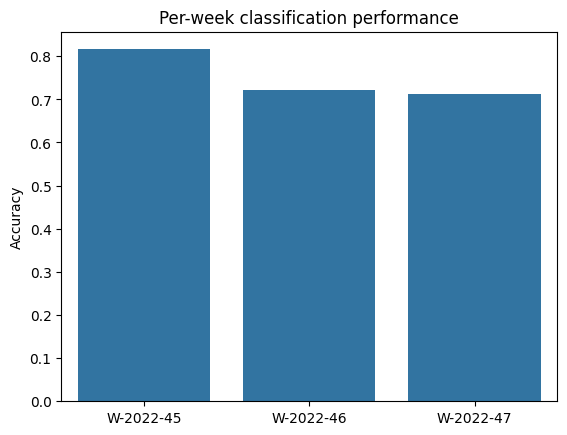

In [ ]:
from sklearn.metrics import accuracy_score
import seaborn

test_periods = ["W-2022-45", "W-2022-46", "W-2022-47"]
per_week_acc = []
for period in test_periods:
    print(f"\nTesting on period {period}")
    dataset_config = DatasetConfig(**common_params, test_period_name=period)
    dataset.set_dataset_config_and_initialize(dataset_config)
    test_df = dataset.get_test_df(flatten_ppi=True)
    print(f"Loaded {len(test_df)} test samples")
    true_labels = test_df.pop(APP_COLUMN)
    preds = lgb_model.predict(test_df).argmax(axis=1)
    acc = accuracy_score(true_labels, preds)
    per_week_acc.append(acc)
    print(f"Classification accuracy for {period} is {acc:.3f}")

seaborn.barplot(y=per_week_acc, x=test_periods).set(title="Per-week classification performance", ylabel="Accuracy");

## Per-day evaluation
Per-week evaluation might be too coarse-grained. Compute per-day performance. The big performance drop is related to a change of Google certificate and is discussed more in the *Encrypted traffic classification: the QUIC case* paper.

In [ ]:
test_dates = ["20221107", "20221108", "20221109", "20221110", "20221111", "20221112", "20221113",
              "20221114", "20221115", "20221116", "20221117", "20221118", "20221119", "20221120",
              "20221121", "20221122", "20221123", "20221124", "20221125", "20221126", "20221127"]
per_date_acc = []
for date in test_dates:
    dataset_config = DatasetConfig(**common_params, test_period_name=date)
    dataset.set_dataset_config_and_initialize(dataset_config)
    test_df = dataset.get_test_df(flatten_ppi=True)
    true_labels = test_df.pop(APP_COLUMN)
    preds = lgb_model.predict(test_df).argmax(axis=1)
    acc = accuracy_score(true_labels, preds)
    per_date_acc.append(acc)

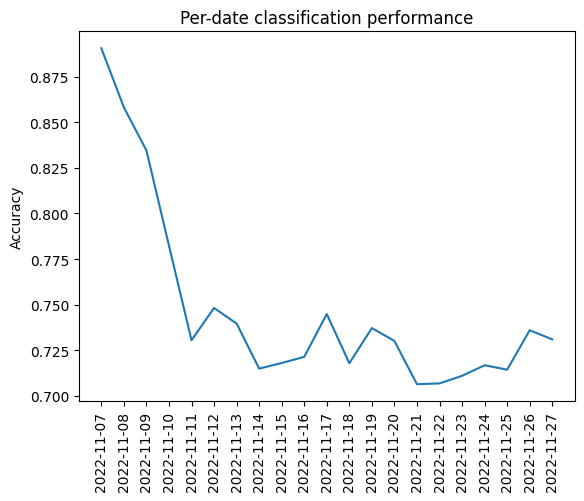

In [ ]:
from matplotlib import pyplot as plt

x_labels = list(map(lambda x: f"{x[:4]}-{x[4:6]}-{x[6:]}", test_dates))
fig, ax = plt.subplots()
seaborn.lineplot(x=range(len(per_date_acc)), y=per_date_acc, ax=ax)
ax.set_xticks(range(len(per_date_acc)))
ax.set_xticklabels(x_labels, rotation=90)
ax.set_ylabel("Accuracy")
ax.set(title="Per-date classification performance");

##XX

In [113]:
# https://drive.google.com/file/d/1IG-omP_l7bRfl62nr8EIQ5LP7doi8h9i/view?usp=sharing

# import gdown
# gdown.download(id="1IG-omP_l7bRfl62nr8EIQ5LP7doi8h9i", output="cesnet\cesnat.zip", quiet=True)

!mkdir /content/cesnety
!gdown 1IG-omP_l7bRfl62nr8EIQ5LP7doi8h9i -O cesnet.zip
!unzip -qq /content/cesnet.zip -d /content/cesnet

mkdir: cannot create directory ‘/content/cesnet’: File exists
Downloading...
From (original): https://drive.google.com/uc?id=1IG-omP_l7bRfl62nr8EIQ5LP7doi8h9i
From (redirected): https://drive.google.com/uc?id=1IG-omP_l7bRfl62nr8EIQ5LP7doi8h9i&confirm=t&uuid=cfae3511-87f6-4035-b037-a87234c30fb4
To: /content/cesnet.zip
100% 1.84G/1.84G [00:37<00:00, 48.6MB/s]
replace /content/cesnet/(cesnet-quic22)-(W-2022-44)-(1_Mon)-flows-20221031.csv.gz? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/cesnet/(cesnet-quic22)-(W-2022-44)-(1_Mon)-stats-20221031.json? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/cesnet/(cesnet-quic22)-(W-2022-44)-(2_Tue)-flows-20221101.csv.gz? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
y
replace /content/cesnet/(cesnet-quic22)-(W-2022-44)-(2_Tue)-stats-20221101.json? [y]es, [n]o, [A]ll, [N]one, [r]ename: replace /content/cesnet/(cesnet-quic22)-README.md? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/cesnet/(cesnet-tls22)-(W-2021-40)-(6_Sat)-fl

In [114]:
import pandas as pd
df = pd.read_csv('/content/cesnet/(cesnet-tls22)-(W-2021-40)-(6_Sat)-flows-20211009.csv.gz', nrows=1_000_000)
df.head(3)

,ID,BYTES,BYTES_REV,PACKETS,PACKETS_REV,DURATION,PPI,PPI_LEN,PPI_DURATION,PPI_ROUNDTRIPS,...,FLAG_ACK,FLAG_ACK_REV,FLAG_PSH,FLAG_PSH_REV,FLAG_RST,FLAG_RST_REV,FLAG_SYN,FLAG_SYN_REV,FLAG_FIN,FLAG_FIN_REV
0,60052691,793,715,5,6,0.008550,"[[0, 1, 3, 0, 0], [1, -1, 1, -1, -1], [517, 21...",5,0.004,2,...,1,1,1,1,0,0,1,1,0,0
1,60052692,2386,4689,11,9,0.098527,"[[0, 5, 0, 0, 10, 36, 15, 16], [1, -1, -1, -1,...",8,0.082,2,...,1,1,1,1,0,0,1,1,1,1
2,60052693,1136,12840,9,16,0.112252,"[[0, 18, 0, 0, 0, 4, 1, 56, 0, 0, 0, 0, 0, 0, ...",15,0.079,2,...,1,1,1,1,0,0,1,1,1,1


In [115]:
df.CATEGORY.value_counts().reset_index()

,CATEGORY,count
0,Analytics & Telemetry,126385
1,Other services and APIs,101861
2,Antivirus,99505
3,Streaming media,95240
4,File sharing,90211
5,Software updates,78208
6,Videoconferencing,67825
7,Social,51314
8,Authentication services,47953
9,Mail,45256


In [116]:
df = df.drop('PPI', axis=1)
df = df.drop('CATEGORY', axis=1)
df.head(3)

,ID,BYTES,BYTES_REV,PACKETS,PACKETS_REV,DURATION,PPI_LEN,PPI_DURATION,PPI_ROUNDTRIPS,APP,...,FLAG_ACK,FLAG_ACK_REV,FLAG_PSH,FLAG_PSH_REV,FLAG_RST,FLAG_RST_REV,FLAG_SYN,FLAG_SYN_REV,FLAG_FIN,FLAG_FIN_REV
0,60052691,793,715,5,6,0.008550,5,0.004,2,facebook-web,...,1,1,1,1,0,0,1,1,0,0
1,60052692,2386,4689,11,9,0.098527,8,0.082,2,bitdefender-nimbus,...,1,1,1,1,0,0,1,1,1,1
2,60052693,1136,12840,9,16,0.112252,15,0.079,2,google-www,...,1,1,1,1,0,0,1,1,1,1


In [ ]:
df.shape

(1000000, 28)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 28 columns):
 #   Column          Non-Null Count    Dtype  
---  ------          --------------    -----  
 0   ID              1000000 non-null  int64  
 1   BYTES           1000000 non-null  int64  
 2   BYTES_REV       1000000 non-null  int64  
 3   PACKETS         1000000 non-null  int64  
 4   PACKETS_REV     1000000 non-null  int64  
 5   DURATION        1000000 non-null  float64
 6   PPI_LEN         1000000 non-null  int64  
 7   PPI_DURATION    1000000 non-null  float64
 8   PPI_ROUNDTRIPS  1000000 non-null  int64  
 9   APP             1000000 non-null  object 
 10  TCP_FLAGS       1000000 non-null  int64  
 11  TCP_FLAGS_REV   1000000 non-null  int64  
 12  FLAG_CWR        1000000 non-null  int64  
 13  FLAG_CWR_REV    1000000 non-null  int64  
 14  FLAG_ECE        1000000 non-null  int64  
 15  FLAG_ECE_REV    1000000 non-null  int64  
 16  FLAG_URG        1000000 non-null  int

In [ ]:
df.PPI[2]

'[[0, 18, 0, 0, 0, 4, 1, 56, 0, 0, 0, 0, 0, 0, 0], [1, -1, -1, -1, -1, 1, 1, -1, -1, -1, -1, -1, -1, -1, -1], [517, 1430, 1430, 1430, 19, 80, 167, 1430, 592, 1430, 1430, 1430, 1228, 312, 27]]'

In [ ]:
df.APP[2]

'google-www'

In [ ]:
df.columns

Index(['ID', 'BYTES', 'BYTES_REV', 'PACKETS', 'PACKETS_REV', 'DURATION',
       'PPI_LEN', 'PPI_DURATION', 'PPI_ROUNDTRIPS', 'APP', 'TCP_FLAGS',
       'TCP_FLAGS_REV', 'FLAG_CWR', 'FLAG_CWR_REV', 'FLAG_ECE', 'FLAG_ECE_REV',
       'FLAG_URG', 'FLAG_URG_REV', 'FLAG_ACK', 'FLAG_ACK_REV', 'FLAG_PSH',
       'FLAG_PSH_REV', 'FLAG_RST', 'FLAG_RST_REV', 'FLAG_SYN', 'FLAG_SYN_REV',
       'FLAG_FIN', 'FLAG_FIN_REV'],
      dtype='object')

In [117]:
df.APP.value_counts().reset_index()['count']
df_c = df.APP.value_counts().reset_index()
df_c = df_c[df_c['count']>1000]
df_c.tail(10)

,APP,count
117,the-weather-channel,1192
118,netflix,1191
119,booking-com,1185
120,gfe-events,1151
121,opera-speeddial,1139
122,firefox-settings,1138
123,apple-pancake,1134
124,ctu-idp2,1108
125,obalkyknih,1068
126,unity-games,1025


In [ ]:
df_c.shape[0]

127

In [ ]:
df_сut = df[ df.APP.isin(df_c.APP) ].reset_index(drop=True)
df_сut.shape

(975312, 28)

In [ ]:
df_сut["APP"] = df_сut["APP"].astype("category")

In [ ]:
df_сut.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 975312 entries, 0 to 975311
Data columns (total 28 columns):
 #   Column          Non-Null Count   Dtype   
---  ------          --------------   -----   
 0   ID              975312 non-null  int64   
 1   BYTES           975312 non-null  int64   
 2   BYTES_REV       975312 non-null  int64   
 3   PACKETS         975312 non-null  int64   
 4   PACKETS_REV     975312 non-null  int64   
 5   DURATION        975312 non-null  float64 
 6   PPI_LEN         975312 non-null  int64   
 7   PPI_DURATION    975312 non-null  float64 
 8   PPI_ROUNDTRIPS  975312 non-null  int64   
 9   APP             975312 non-null  category
 10  TCP_FLAGS       975312 non-null  int64   
 11  TCP_FLAGS_REV   975312 non-null  int64   
 12  FLAG_CWR        975312 non-null  int64   
 13  FLAG_CWR_REV    975312 non-null  int64   
 14  FLAG_ECE        975312 non-null  int64   
 15  FLAG_ECE_REV    975312 non-null  int64   
 16  FLAG_URG        975312 non-null  int64

In [ ]:
import lightgbm as lgb
from sklearn.model_selection import train_test_split

APP_COLUMN = "APP"

# все колонки, кроме метки, считаем признаками
feature_names = [c for c in df_сut.columns if c != APP_COLUMN]

train_df, val_df = train_test_split(
    df_сut,
    test_size=0.2,
    random_state=42,
    stratify=df_сut[APP_COLUMN],  # можно убрать, если стратификация не нужна
)

train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)

train_labels = feature_names # train_df.pop(APP_COLUMN)
val_labels   = feature_names # val_df.pop(APP_COLUMN)

lgb_train_dataset = lgb.Dataset(data=train_df, label=train_labels, feature_name=feature_names)
lgb_val_dataset   = lgb.Dataset(data=val_df,   label=val_labels,   feature_name=feature_names)

print(f"Loaded {len(train_df)} train samples")
print(f"Loaded {len(val_df)} validation samples")

Loaded 780249 train samples
Loaded 195063 validation samples


In [ ]:
feature_names

['ID',
 'BYTES',
 'BYTES_REV',
 'PACKETS',
 'PACKETS_REV',
 'DURATION',
 'PPI_LEN',
 'PPI_DURATION',
 'PPI_ROUNDTRIPS',
 'TCP_FLAGS',
 'TCP_FLAGS_REV',
 'FLAG_CWR',
 'FLAG_CWR_REV',
 'FLAG_ECE',
 'FLAG_ECE_REV',
 'FLAG_URG',
 'FLAG_URG_REV',
 'FLAG_ACK',
 'FLAG_ACK_REV',
 'FLAG_PSH',
 'FLAG_PSH_REV',
 'FLAG_RST',
 'FLAG_RST_REV',
 'FLAG_SYN',
 'FLAG_SYN_REV',
 'FLAG_FIN',
 'FLAG_FIN_REV']

In [ ]:
train_df.head(3)

,ID,BYTES,BYTES_REV,PACKETS,PACKETS_REV,DURATION,PPI_LEN,PPI_DURATION,PPI_ROUNDTRIPS,APP,...,FLAG_ACK,FLAG_ACK_REV,FLAG_PSH,FLAG_PSH_REV,FLAG_RST,FLAG_RST_REV,FLAG_SYN,FLAG_SYN_REV,FLAG_FIN,FLAG_FIN_REV
0,60409522,4245,4253,11,7,0.090961,10,0.045,3,rubiconproject,...,1,1,1,1,0,0,1,1,0,0
1,60894951,1862,1386,9,7,3.166204,5,0.081,2,google-www,...,1,1,1,1,0,0,1,1,1,1
2,60255679,4879,5620,13,11,1.021709,14,0.682,4,microsoft-diagnostic,...,1,1,1,1,0,0,1,1,1,1


In [ ]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 780249 entries, 0 to 780248
Data columns (total 28 columns):
 #   Column          Non-Null Count   Dtype   
---  ------          --------------   -----   
 0   ID              780249 non-null  int64   
 1   BYTES           780249 non-null  int64   
 2   BYTES_REV       780249 non-null  int64   
 3   PACKETS         780249 non-null  int64   
 4   PACKETS_REV     780249 non-null  int64   
 5   DURATION        780249 non-null  float64 
 6   PPI_LEN         780249 non-null  int64   
 7   PPI_DURATION    780249 non-null  float64 
 8   PPI_ROUNDTRIPS  780249 non-null  int64   
 9   APP             780249 non-null  category
 10  TCP_FLAGS       780249 non-null  int64   
 11  TCP_FLAGS_REV   780249 non-null  int64   
 12  FLAG_CWR        780249 non-null  int64   
 13  FLAG_CWR_REV    780249 non-null  int64   
 14  FLAG_ECE        780249 non-null  int64   
 15  FLAG_ECE_REV    780249 non-null  int64   
 16  FLAG_URG        780249 non-null  int64

In [ ]:
lgb_params = {
    "task"            : "train",
    "objective"       : "multiclass",
    "num_class"       : df_c.shape[0],    #dataset.get_num_classes(),
    "metric"          : "multi_error",
    "num_leaves"      : 320,
    "min_data_in_leaf": 20,
    "feature_fraction": 0.8,
    "lambda_l2"       : 4,
    "verbose"         : -1,
}

validation_metrics = {}
lgb_model = lgb.train(
    params          = lgb_params,
    num_boost_round = 20,
    train_set       = lgb_train_dataset,
    valid_sets      = [lgb_val_dataset],
    callbacks       = [lgb.log_evaluation()]
)
best_score = lgb_model.best_score["valid_0"]["multi_error"]
print(f"The best validation score is {best_score:.3f}")

TypeError: Wrong type(str) or unknown name(APP) in categorical_feature

In [ ]:
import pandas as pd
import lightgbm as lgb
from sklearn.model_selection import train_test_split

# ---------------------------------------------------------------
# 1) Загрузка данных
# ---------------------------------------------------------------
df = pd.read_csv(
    '/content/cesnet/(cesnet-tls22)-(W-2021-40)-(6_Sat)-flows-20211009.csv.gz',
    nrows=1_000_000,
)

# Убираем колонки, которые не пойдут в модель
df = df.drop('PPI', axis=1)
df = df.drop('CATEGORY', axis=1)

# ---------------------------------------------------------------
# 2) Фильтрация редких классов (>1000 примеров)
# ---------------------------------------------------------------
df.APP.value_counts().reset_index()['count']  # для наглядности

df_c = df.APP.value_counts().reset_index()
df_c = df_c[df_c['count'] > 1000]

df_cut = df[df.APP.isin(df_c.APP)].reset_index(drop=True)

print("Распределение классов после фильтрации:")
print(df_cut.APP.value_counts())

# ---------------------------------------------------------------
# 3) Признаки и метка
# ---------------------------------------------------------------
APP_COLUMN = "APP"

# Метку приводим к category, чтобы потом взять .cat.codes
df_cut[APP_COLUMN] = df_cut[APP_COLUMN].astype("category")
app_categories = df_cut[APP_COLUMN].cat.categories
num_class = len(app_categories)

# Признаки — все колонки, кроме метки
feature_names = [c for c in df_cut.columns if c != APP_COLUMN]

# ---------------------------------------------------------------
# 4) Train/val 80/20 со стратификацией
# ---------------------------------------------------------------
train_df, val_df = train_test_split(
    df_cut,
    test_size=0.2,
    random_state=42,
    stratify=df_cut[APP_COLUMN],
)
train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)

# Метки: pop + приведение к целочисленным кодам 0..num_class-1
# pop удаляет колонку APP из датафрейма признаков (модель не должна "видеть" ответ во время обучения).
# .cat.codes преобразует текстовые названия приложений в целые числа от 0 до num_class - 1. LightGBM требует, чтобы метки классов были именно числами
train_labels = train_df.pop(APP_COLUMN).cat.set_categories(app_categories).cat.codes
val_labels   = val_df.pop(APP_COLUMN).cat.set_categories(app_categories).cat.codes

# Дополнительная страховка: оставляем в X только признаки
train_df = train_df[feature_names]
val_df   = val_df[feature_names]

assert APP_COLUMN not in train_df.columns
assert APP_COLUMN not in val_df.columns
assert len(train_df) == len(train_labels)
assert len(val_df) == len(val_labels)

print(f"Loaded {len(train_df)} train samples")
print(f"Loaded {len(val_df)} validation samples")
print(f"Features ({len(feature_names)}): {feature_names}")
print(f"num_class: {num_class}")

# ---------------------------------------------------------------
# 5) Датасеты LightGBM
# ---------------------------------------------------------------
lgb_train_dataset = lgb.Dataset(
    data=train_df, label=train_labels, feature_name=feature_names
)
lgb_val_dataset = lgb.Dataset(
    data=val_df, label=val_labels, feature_name=feature_names
)



Распределение классов после фильтрации:
APP
microsoft-update        66502
microsoft-diagnostic    56748
microsoft-settings      54347
outlook                 37242
skype                   34362
                        ...  
firefox-settings         1138
apple-pancake            1134
ctu-idp2                 1108
obalkyknih               1068
unity-games              1025
Name: count, Length: 127, dtype: int64
Loaded 780249 train samples
Loaded 195063 validation samples
Features (27): ['ID', 'BYTES', 'BYTES_REV', 'PACKETS', 'PACKETS_REV', 'DURATION', 'PPI_LEN', 'PPI_DURATION', 'PPI_ROUNDTRIPS', 'TCP_FLAGS', 'TCP_FLAGS_REV', 'FLAG_CWR', 'FLAG_CWR_REV', 'FLAG_ECE', 'FLAG_ECE_REV', 'FLAG_URG', 'FLAG_URG_REV', 'FLAG_ACK', 'FLAG_ACK_REV', 'FLAG_PSH', 'FLAG_PSH_REV', 'FLAG_RST', 'FLAG_RST_REV', 'FLAG_SYN', 'FLAG_SYN_REV', 'FLAG_FIN', 'FLAG_FIN_REV']
num_class: 127
[1]	valid_0's multi_error: 0.275055
[2]	valid_0's multi_error: 0.229731
[3]	valid_0's multi_error: 0.200197
[4]	valid_0's multi_er

In [ ]:
# ---------------------------------------------------------------
# 6) Параметры и обучение
# ---------------------------------------------------------------
lgb_params = {
    "objective"       : "multiclass",
    "num_class"       : num_class,
    "metric"          : ["multi_error", "multi_logloss"],
    "num_leaves"      : 320,
    "min_data_in_leaf": 20,
    "feature_fraction": 0.8,
    "lambda_l2"       : 4,
    "verbose"         : -1,
    "num_threads": -1,  # Использовать все доступные ядра
    # "device_type": "gpu",
}

lgb_model = lgb.train(
    params=lgb_params,
    num_boost_round=100,
    train_set=lgb_train_dataset,
    # valid_sets=[lgb_val_dataset],
    valid_sets=[lgb_train_dataset, lgb_val_dataset],
    valid_names=['train', 'valid'],  # <-- ВАЖНО: задаем понятные имена
    callbacks=[lgb.early_stopping(stopping_rounds=5), lgb.log_evaluation()],
)

best_score = lgb_model.best_score["valid_0"]["multi_error"]
print(f"The best validation score is {best_score:.3f}")

[1]	training's multi_error: 0.270447	training's multi_logloss: 1.81102	valid_1's multi_error: 0.275055	valid_1's multi_logloss: 1.83716
Training until validation scores don't improve for 5 rounds
[2]	training's multi_error: 0.221237	training's multi_logloss: 1.49345	valid_1's multi_error: 0.229731	valid_1's multi_logloss: 1.53495
[3]	training's multi_error: 0.189556	training's multi_logloss: 1.28684	valid_1's multi_error: 0.200197	valid_1's multi_logloss: 1.33879
[4]	training's multi_error: 0.169663	training's multi_logloss: 1.13865	valid_1's multi_error: 0.182961	valid_1's multi_logloss: 1.19942
[5]	training's multi_error: 0.155443	training's multi_logloss: 1.01908	valid_1's multi_error: 0.170304	valid_1's multi_logloss: 1.08743
[6]	training's multi_error: 0.144999	training's multi_logloss: 0.921869	valid_1's multi_error: 0.161066	valid_1's multi_logloss: 0.997011
[7]	training's multi_error: 0.136153	training's multi_logloss: 0.840639	valid_1's multi_error: 0.153581	valid_1's multi_lo

In [118]:
import pandas as pd
import lightgbm as lgb
from lightgbm import LGBMClassifier  # <--- ИЗМЕНЕНО: импортируем sklearn-класс
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt       # <--- ДОБАВЛЕНО: для графиков

# ---------------------------------------------------------------
# 1) Загрузка данных
# ---------------------------------------------------------------
df = pd.read_csv(
    '/content/cesnet/(cesnet-tls22)-(W-2021-40)-(6_Sat)-flows-20211009.csv.gz',
    nrows=1_000_000,
)

df = df.drop('PPI', axis=1)
df = df.drop('CATEGORY', axis=1)

# ---------------------------------------------------------------
# 2) Фильтрация редких классов (>1000 примеров)
# ---------------------------------------------------------------
df_c = df.APP.value_counts().reset_index()
df_c = df_c[df_c['count'] > 1000]
df_cut = df[df.APP.isin(df_c.APP)].reset_index(drop=True)

print("Распределение классов после фильтрации:")
print(df_cut.APP.value_counts())

# ---------------------------------------------------------------
# 3) Признаки и метка
# ---------------------------------------------------------------
APP_COLUMN = "APP"

df_cut[APP_COLUMN] = df_cut[APP_COLUMN].astype("category")
app_categories = df_cut[APP_COLUMN].cat.categories
num_class = len(app_categories)

feature_names = [c for c in df_cut.columns if c != APP_COLUMN]

# ---------------------------------------------------------------
# 4) Train/val 80/20 со стратификацией
# ---------------------------------------------------------------
train_df, val_df = train_test_split(
    df_cut,
    test_size=0.2,
    random_state=42,
    stratify=df_cut[APP_COLUMN],
)
train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)

train_labels = train_df.pop(APP_COLUMN).cat.set_categories(app_categories).cat.codes
val_labels   = val_df.pop(APP_COLUMN).cat.set_categories(app_categories).cat.codes

train_df = train_df[feature_names]
val_df   = val_df[feature_names]

print(f"Loaded {len(train_df)} train samples")
print(f"Loaded {len(val_df)} validation samples")
print(f"Features ({len(feature_names)}): {feature_names}")
print(f"num_class: {num_class}")







Распределение классов после фильтрации:
APP
microsoft-update        66502
microsoft-diagnostic    56748
microsoft-settings      54347
outlook                 37242
skype                   34362
                        ...  
firefox-settings         1138
apple-pancake            1134
ctu-idp2                 1108
obalkyknih               1068
unity-games              1025
Name: count, Length: 127, dtype: int64
Loaded 780249 train samples
Loaded 195063 validation samples
Features (27): ['ID', 'BYTES', 'BYTES_REV', 'PACKETS', 'PACKETS_REV', 'DURATION', 'PPI_LEN', 'PPI_DURATION', 'PPI_ROUNDTRIPS', 'TCP_FLAGS', 'TCP_FLAGS_REV', 'FLAG_CWR', 'FLAG_CWR_REV', 'FLAG_ECE', 'FLAG_ECE_REV', 'FLAG_URG', 'FLAG_URG_REV', 'FLAG_ACK', 'FLAG_ACK_REV', 'FLAG_PSH', 'FLAG_PSH_REV', 'FLAG_RST', 'FLAG_RST_REV', 'FLAG_SYN', 'FLAG_SYN_REV', 'FLAG_FIN', 'FLAG_FIN_REV']
num_class: 127


In [122]:
# ---------------------------------------------------------------
# 5) Инициализация модели (Sklearn API)
# ---------------------------------------------------------------
# <--- ИЗМЕНЕНО: Вместо словаря lgb_params и lgb.Dataset,
# мы передаем параметры прямо в конструктор класса.
# Примечание: LightGBM понимает свои оригинальные имена параметров (min_data_in_leaf и т.д.),
# но num_threads здесь называется n_jobs, а num_boost_round -> n_estimators.

lgb_model = LGBMClassifier(
    objective='multiclass',
    num_class=num_class,
    num_leaves=100,
    min_data_in_leaf=20,       # В sklearn API также работает как min_child_samples
    feature_fraction=0.8,      # Также работает как colsample_bytree
    lambda_l2=4,               # Также работает как reg_lambda
    n_estimators=50,          # Аналог num_boost_round
    n_jobs=-1,                 # Аналог num_threads (использовать все ядра)
    random_state=42,
    verbose=-1                 # Скрывает внутренние предупреждения
)


# ---------------------------------------------------------------
# 6) Обучение модели (Sklearn API)
# ---------------------------------------------------------------
# <--- ИЗМЕНЕНО: Используем метод .fit() вместо lgb.train()
# eval_set принимает список кортежей (X, y)

lgb_model.fit(
    X=train_df,
    y=train_labels,
    # ИСПРАВЛЕНО: второй элемент кортежа должен быть val_labels, а не val_df
    eval_set=[(train_df, train_labels), (val_df, val_labels)],
    eval_metric='multi_error',
    # eval_metric=['multi_error', 'multi_logloss'],
    callbacks=[
        lgb.early_stopping(stopping_rounds=3),
        lgb.log_evaluation(period=1)
    ]
)

Training until validation scores don't improve for 3 rounds
[10]	training's multi_error: 0.142194	training's multi_logloss: 0.771375	valid_1's multi_error: 0.155509	valid_1's multi_logloss: 0.832946
[20]	training's multi_error: 0.113088	training's multi_logloss: 0.508124	valid_1's multi_error: 0.132188	valid_1's multi_logloss: 0.590877
[30]	training's multi_error: 0.0959681	training's multi_logloss: 0.400282	valid_1's multi_error: 0.119802	valid_1's multi_logloss: 0.501207
[40]	training's multi_error: 0.0838527	training's multi_logloss: 0.337872	valid_1's multi_error: 0.112343	valid_1's multi_logloss: 0.455277
[50]	training's multi_error: 0.0741891	training's multi_logloss: 0.294475	valid_1's multi_error: 0.10735	valid_1's multi_logloss: 0.426581
Did not meet early stopping. Best iteration is:
[50]	training's multi_error: 0.0741891	training's multi_logloss: 0.294475	valid_1's multi_error: 0.10735	valid_1's multi_logloss: 0.426581


LGBMClassifier(feature_fraction=0.8, lambda_l2=4, min_data_in_leaf=20,
               n_estimators=50, n_jobs=-1, num_class=127, num_leaves=100,
               objective='multiclass', random_state=42, verbose=-1)

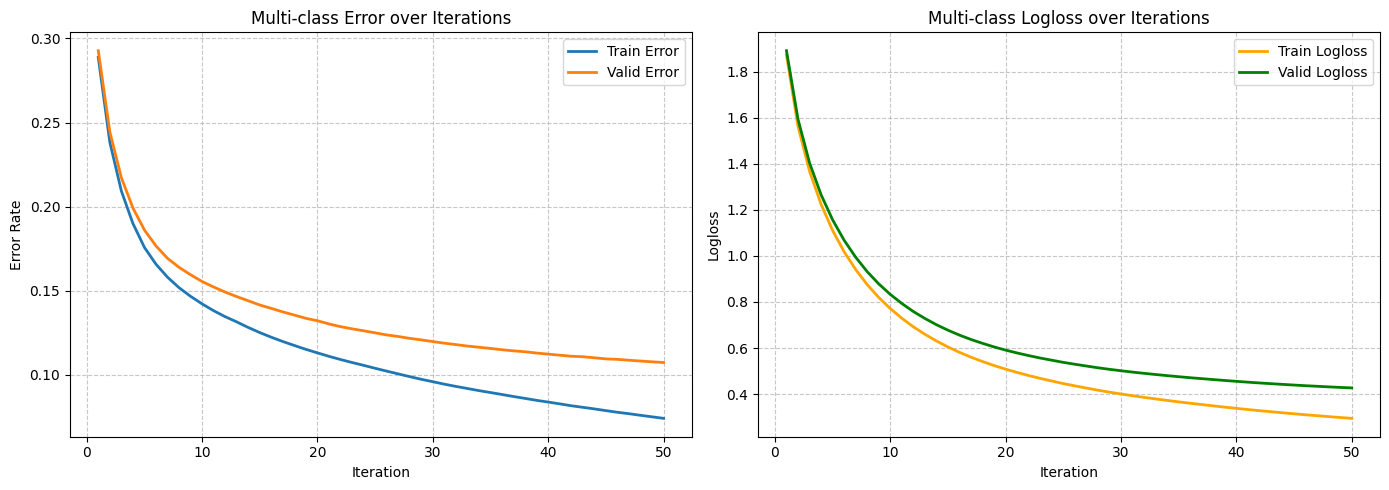


✅ Обучение завершено!
Лучшая итерация (Early Stopping): 50
Лучший validation multi_error: 0.107


In [125]:
# ---------------------------------------------------------------
# 7) Извлечение результатов и визуализация
# ---------------------------------------------------------------
history = lgb_model.evals_result_

# ИСПРАВЛЕНО: Ключи берутся из вашей структуры данных
train_key = 'training'  # <-- Было 'valid_0'
val_key = 'valid_1'     # <-- Осталось без изменений

iterations = range(1, len(history[train_key]['multi_error']) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# График 1: Error
ax1.plot(iterations, history[train_key]['multi_error'],
         label='Train Error', linewidth=2)
ax1.plot(iterations, history[val_key]['multi_error'],
         label='Valid Error', linewidth=2)
ax1.set_title('Multi-class Error over Iterations')
ax1.set_xlabel('Iteration')
ax1.set_ylabel('Error Rate')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.7)

# График 2: Logloss
ax2.plot(iterations, history[train_key]['multi_logloss'],
         label='Train Logloss', linewidth=2, color='orange')
ax2.plot(iterations, history[val_key]['multi_logloss'],
         label='Valid Logloss', linewidth=2, color='green')
ax2.set_title('Multi-class Logloss over Iterations')
ax2.set_xlabel('Iteration')
ax2.set_ylabel('Logloss')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

# Получение лучшего результата
best_iter = lgb_model.best_iteration_
best_score = history[val_key]['multi_error'][best_iter - 1]

print(f"\n✅ Обучение завершено!")
print(f"Лучшая итерация (Early Stopping): {best_iter}")
print(f"Лучший validation multi_error: {best_score:.3f}")

In [124]:
history

{'training': OrderedDict([('multi_error',
               [np.float64(0.28871680707056335),
                np.float64(0.2382547109961051),
                np.float64(0.20930625992471635),
                np.float64(0.19002523553378473),
                np.float64(0.1757695299833771),
                np.float64(0.16579194590444846),
                np.float64(0.1580841500597886),
                np.float64(0.15182717312037566),
                np.float64(0.14670444947702593),
                np.float64(0.14219435077776454),
                np.float64(0.13815333310263775),
                np.float64(0.13459421287307),
                np.float64(0.13151570844691887),
                np.float64(0.12818343887656378),
                np.float64(0.12514851028325574),
                np.float64(0.12239169803485811),
                np.float64(0.11983482196068178),
                np.float64(0.11748044534501166),
                np.float64(0.11518246098360908),
                np.float64(0.1130